# Project: Machine Learning in Business

# Project Description

An oil mining company needs to choose the location for drilling a new well.

**Goals and tasks**
- Oil samples were taken in three regions (10,000 wells in each), and the quality of the oil and the volume of its reserves were measured.
- Build a machine learning model that helps to choose the region where mining brings the highest profit.
- Analyze possible profit and risks with the *bootstrap* technique.

**Steps to choose the location:**
- Search for deposits in the chosen region and determine feature values for each of them.
- Build a model and estimate the volume of reserves.
- Select the deposits with the highest estimates. The number of deposits depends on the company's budget and the cost of developing one well.
- The profit equals the total profit of the selected deposits.

**Data description**
The geological exploration data of the three regions is stored in the files `geo_data_0.csv`, `geo_data_1.csv`, `geo_data_2.csv`.
- `id` - unique well identifier;
- `f0`, `f1`, `f2` - three features of the points (their meaning is unknown, but the features are significant);
- `product` - volume of reserves in the well (thousand barrels).

**Conditions:**
- Use a linear regression model (the other models are not predictable enough).
- Explore 500 points during exploration and select the 200 with the highest reserves to calculate the profit.
- The budget for developing the wells in the region is 10 billion rubles.
- One barrel of oil brings 450 rubles of revenue. Volumes are given in thousands of barrels.
- Choose the regions where the probability of losses is below 2.5%. Among the regions that pass the risk assessment, choose the one with the highest average profit.

**Plan:**
- 1. Data loading and preparation
- 2. Model training and validation
- 3. Preparation for profit calculation
- 4. Profit and risk calculation
    - 4.1 Profit calculation
    - 4.2 Risk calculation
- 5. Overall conclusion

# 1. Data Loading and Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from numpy.random import RandomState
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

Load the data and print the first 10 rows of each table. Use `info()` to check the table structure: data types, number of rows and columns, missing values.

In [2]:
def data_read_exam(file_path):
    """
    input:        file_path [object] - path to the file
    output:       data [DataFrame] - data table
    description:  loads the table with read_csv, prints the first 10 rows,
                  prints the data info with info() and counts duplicates
    """
    # read the data from the .csv file
    data = pd.read_csv(file_path)
    display(data.head(10))
    display(data.info())
    print('Number of duplicates:', sum(data.duplicated()))
    return data

In [3]:
geo0 = data_read_exam('geo_data_0.csv')

,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647
5,wX4Hy,0.969570,0.489775,-0.735383,64.741541
6,tL6pL,0.645075,0.530656,1.780266,49.055285
7,BYPU6,-0.400648,0.808337,-5.624670,72.943292
8,j9Oui,0.643105,-0.551583,2.372141,113.356160
9,OLuZU,2.173381,0.563698,9.441852,127.910945


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


None

Number of duplicates: 0


In [4]:
geo1 = data_read_exam('geo_data_1.csv')

,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305
5,HHckp,-3.327590,-2.205276,3.003647,84.038886
6,h5Ujo,-11.142655,-10.133399,4.002382,110.992147
7,muH9x,4.234715,-0.001354,2.004588,53.906522
8,YiRkx,13.355129,-0.332068,4.998647,134.766305
9,jG6Gi,1.069227,-11.025667,4.997844,137.945408


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


None

Number of duplicates: 0


In [5]:
geo2 = data_read_exam('geo_data_2.csv')

,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746
5,LzZXx,-0.758092,0.710691,2.585887,90.222465
6,WBHRv,-0.574891,0.317727,1.773745,45.641478
7,XO8fn,-1.906649,-2.458350,-0.177097,72.480640
8,ybmQ5,1.776292,-0.279356,3.004156,106.616832
9,OilcN,-1.214452,-0.439314,5.922514,52.954532


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


None

Number of duplicates: 0


- The data matches the description. There are no missing values or duplicates.
- The data types match the description.
- Look at the distribution histograms.

In [6]:
def show_hists(data, data_label, num_bins, rug=False, log_scale=False):
    """
    input: data - data for the histogram
           data_label - data description
           num_bins - number of bins
    output: None
    description: builds a histogram and a boxplot for the chosen parameter:
                - density of the distribution (seaborn distplot())
                - boxplot (seaborn boxplot())
    """
    sns.set()
    f, axes = plt.subplots(1, 2, figsize=(16, 4))
    axes[0].set_title(data_label + ". Distribution density", fontsize=18)
    axes[0].set_ylabel('density', fontsize=15)
    sns.distplot(data, bins=num_bins, rug=rug, ax=axes[0])
    axes[1].set_title(data_label + ". Boxplot", fontsize=18)
    sns.boxplot(data=data, ax=axes[1])
    plt.show()

In [7]:
def show_region(data, name):
    numerics = ['f0', 'f1', 'f2', 'product']
    for column in numerics:
        show_hists(data[column], name + ' ' + column, num_bins=20)

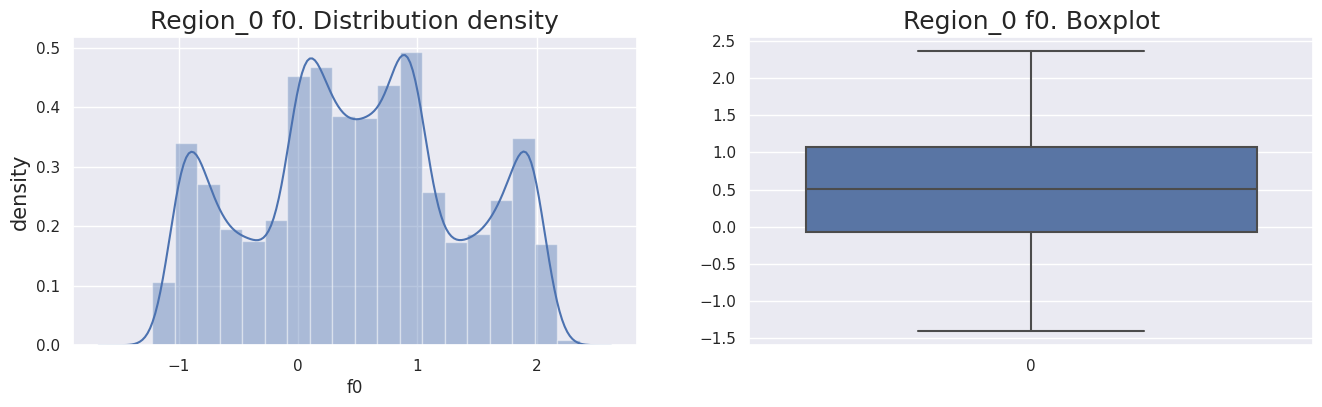

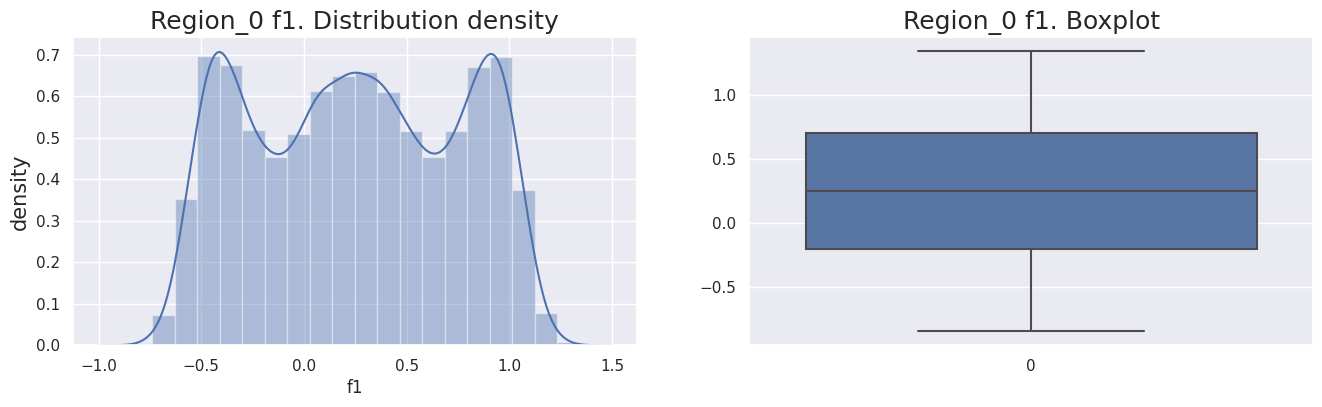

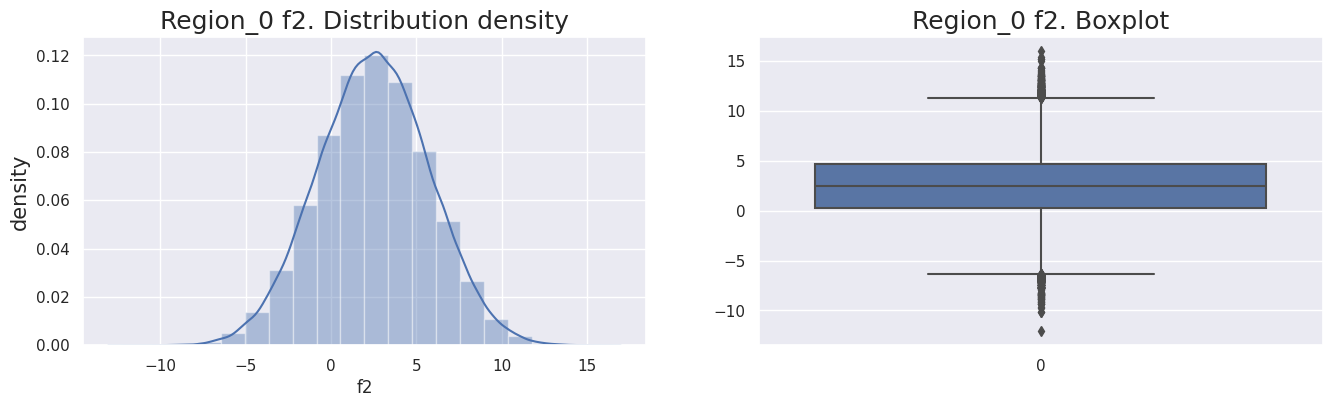

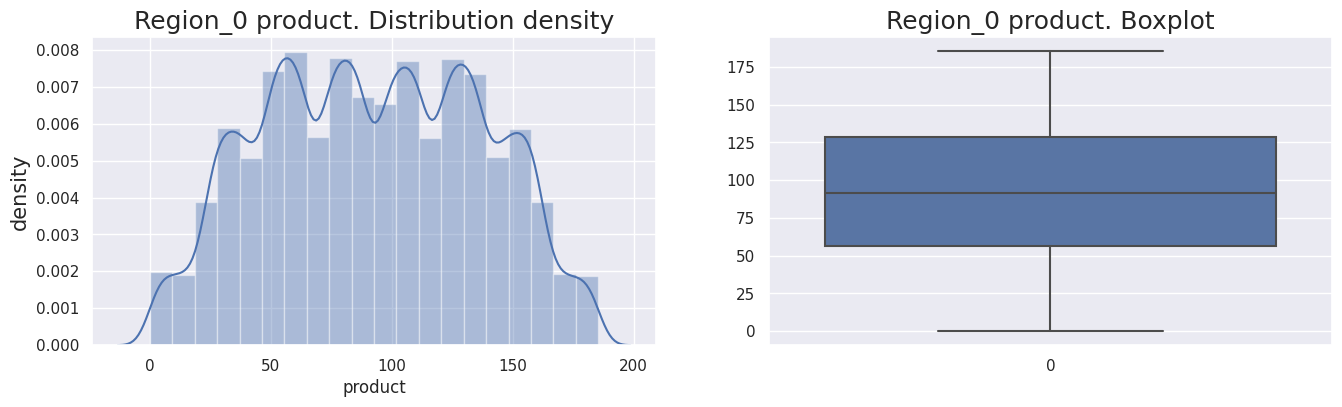

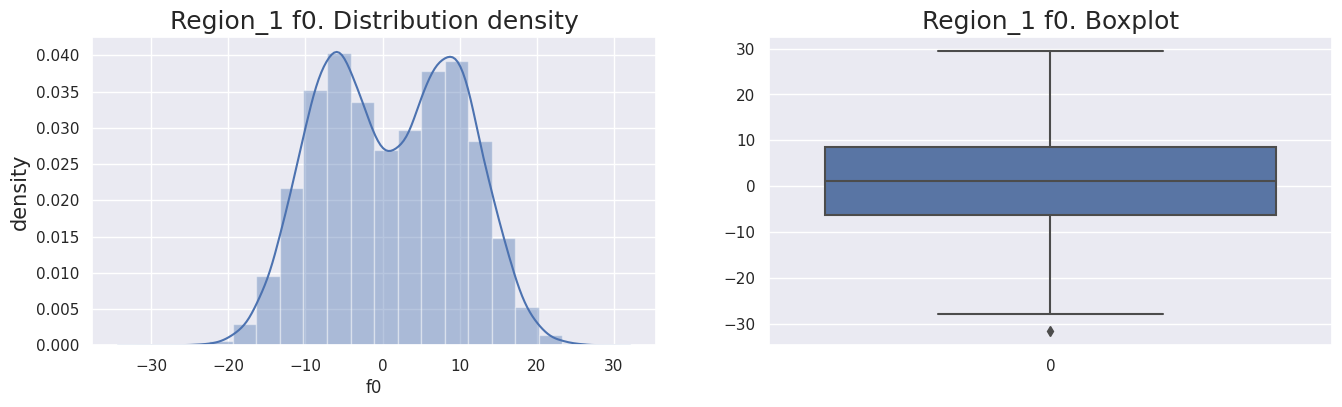

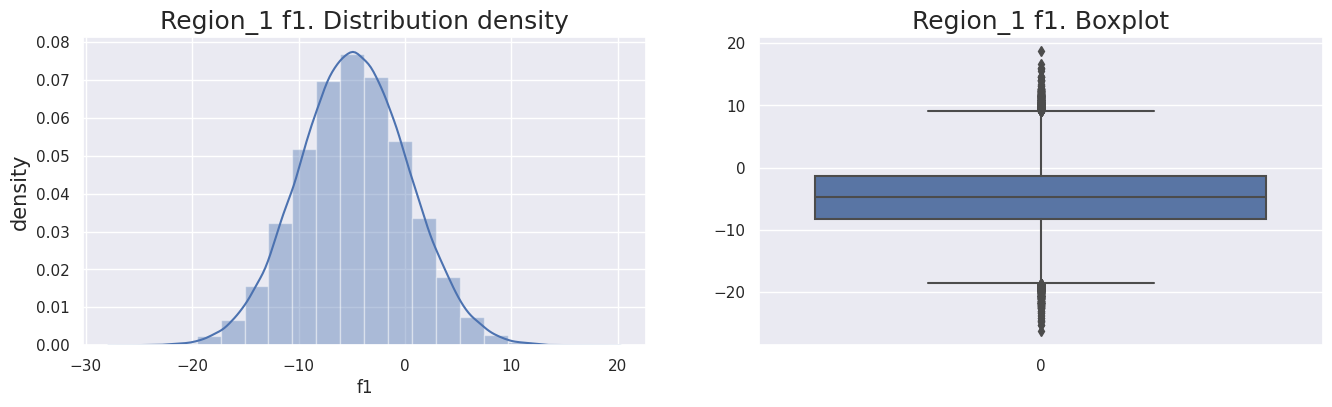

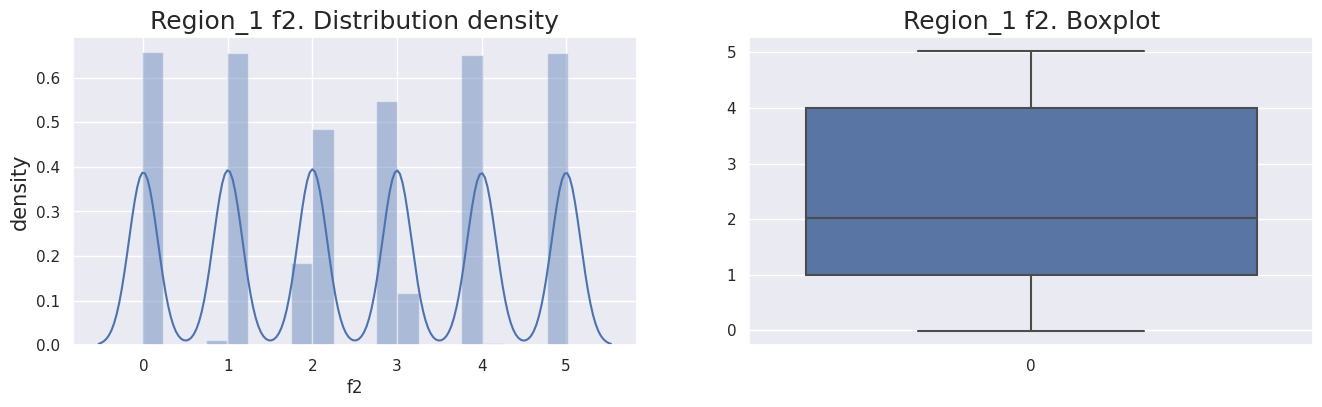

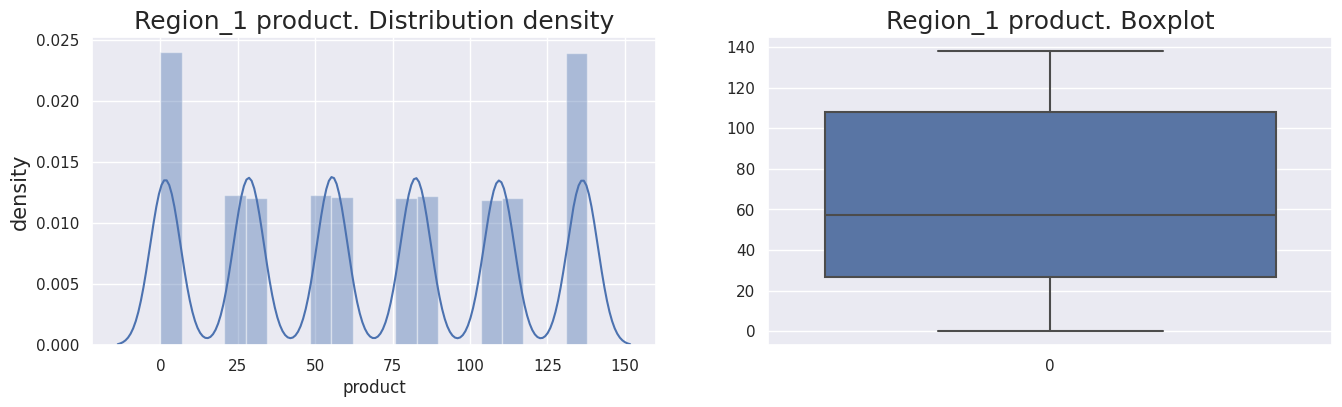

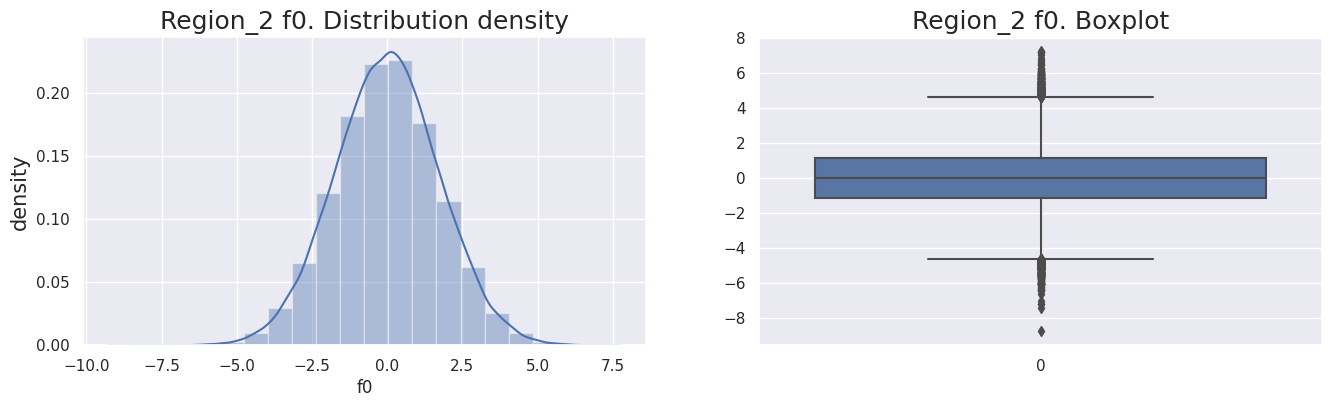

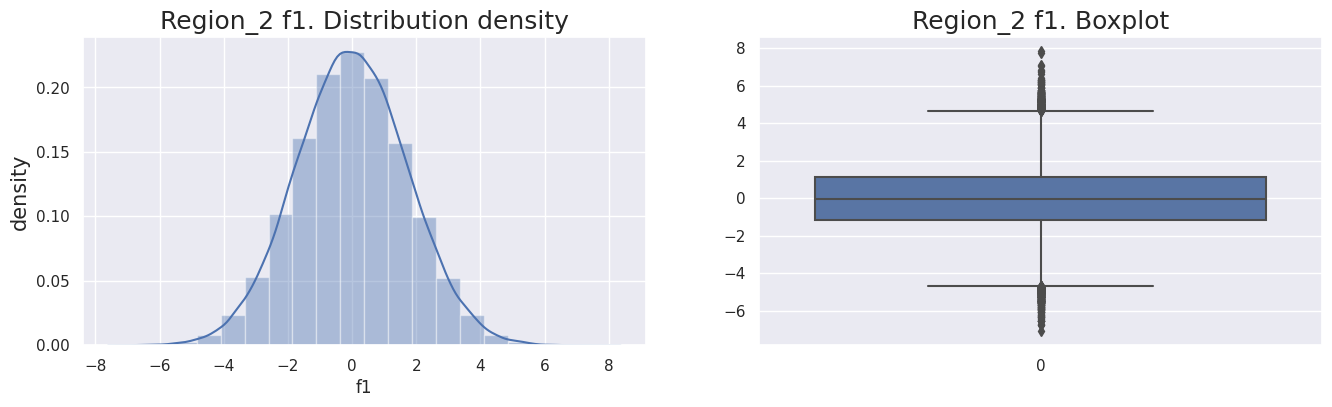

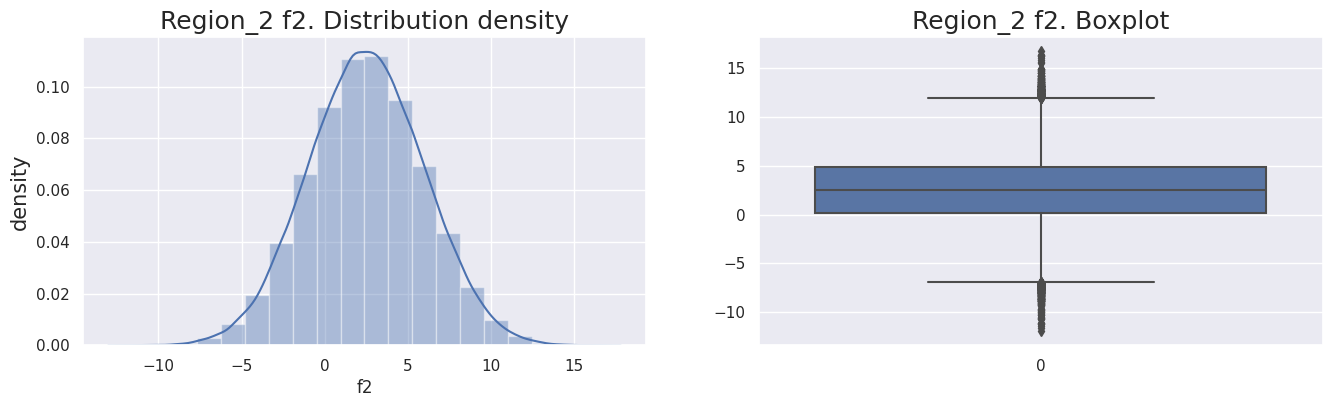

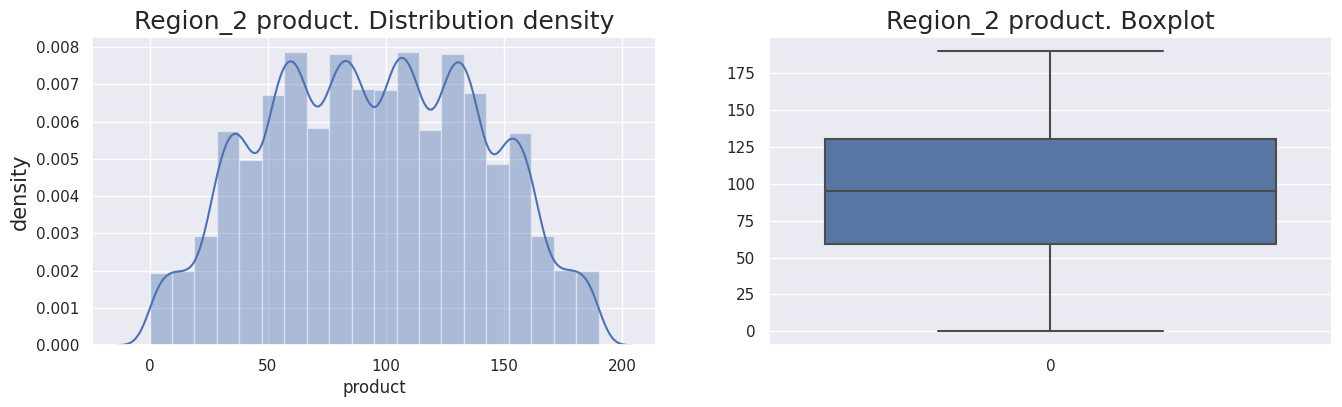

In [8]:
for data, name in [(geo0, 'Region_0'), (geo1, 'Region_1'), (geo2, 'Region_2')]:
    show_region(data, name)

- The distributions of some features differ from the normal one, and there are small outliers. The meaning of the features is unknown, so it is hard to judge whether the distributions and outliers are adequate.
- The scales of the features f0, f1, f2 are close to each other (less than one order of magnitude), so scaling is not needed.
- The data is left as is for now.
- Split the data into features and the target.

In [9]:
feature_names = ['f0', 'f1', 'f2']
target_name = ['product']
X_0 = geo0[feature_names]
y_0 = geo0[target_name]
X_1 = geo1[feature_names]
y_1 = geo1[target_name]
X_2 = geo2[feature_names]
y_2 = geo2[target_name]

### Conclusions

- The data is loaded and analyzed. It matches the description, with no missing values or duplicates and correct data types.
- The distributions of some features differ from the normal one, and there are small outliers. The meaning of the features is unknown, so it is hard to judge whether they are adequate. The data is left unchanged.

# 2. Model Training and Validation

For each region:
- Split the data into training and validation sets.
- Use the linear regression model, as the task requires.
- Print the average predicted volume of reserves and the RMSE of the model.

In [10]:
def model_fit_valid(X, y):
    """
    input: X, y - features and target of the model
    output: y_valid - target of the validation set
            predict - model predictions on the validation set
    description: splits the data into training and validation sets (75/25),
                 trains a linear regression model, predicts on the validation set,
                 calculates and prints the average prediction and the RMSE of the model.
    """
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=42)
    print('Train shape:', X_train.shape)
    print('Valid shape:', X_valid.shape)

    model = LinearRegression()
    model.fit(X_train, y_train)
    predict = model.predict(X_valid)

    predict_mean = predict.mean()
    rmse = mean_squared_error(y_valid, predict)**.5

    print('Average predicted volume of reserves: {:.4f}'.format(predict_mean))
    print('Model RMSE: {:.4f}'.format(rmse))

    return y_valid, predict

- **Region 0**

In [11]:
y_0_valid, predict_0 = model_fit_valid(X_0, y_0)

Train shape: (75000, 3)
Valid shape: (25000, 3)
Average predicted volume of reserves: 92.3988
Model RMSE: 37.7566


- **Region 1**

In [12]:
y_1_valid, predict_1 = model_fit_valid(X_1, y_1)

Train shape: (75000, 3)
Valid shape: (25000, 3)
Average predicted volume of reserves: 68.7129
Model RMSE: 0.8903


- **Region 2**

In [13]:
y_2_valid, predict_2 = model_fit_valid(X_2, y_2)

Train shape: (75000, 3)
Valid shape: (25000, 3)
Average predicted volume of reserves: 94.7710
Model RMSE: 40.1459


### Conclusions

- Regions 0 and 2 have a high average predicted volume of reserves (**92.4** and **94.8**). Their RMSE is also high (**37.8** and **40.1**), so the predictions are imprecise.
- Region 1 has the lowest average predicted volume of reserves (**68.7**), but its RMSE is very small (**0.9**). The model predicts this region accurately.

# 3. Preparation for Profit Calculation

- Calculate the volume of reserves sufficient for break-even development of a new well.
- Compare it with the average reserves in each region.

- **min_product = budget / (top_wells * unit_income)**
    - budget - budget for developing the wells in the region, 10 billion rubles
    - top_wells, samp_wells - the 200 best wells are chosen out of 500 in the sample
    - unit_income - revenue per unit of product, 450 thousand rubles

In [14]:
BUDGET = 10**10
TOP_WELLS = 200
SAMP_WELLS = 500
UNIT_INCOME = 4.5*10**5

In [15]:
min_product = BUDGET / (TOP_WELLS * UNIT_INCOME)
print('Minimum volume of reserves per well for break-even development: {:.2f}'.format(min_product))

Minimum volume of reserves per well for break-even development: 111.11


### Conclusions

- The minimum volume of reserves for break-even development is **111.11**, calculated for the 200 best wells out of 500 in the sample.
- This value is higher than the average reserves of the wells in all regions.

# 4. Profit and Risk Calculation

## 4.1 Profit Calculation

Write a function that calculates the profit for the selected wells and the model predictions:
- Select the wells with the highest predictions. The number of wells depends on the company's budget and the cost of developing one well. Here 500 points are chosen randomly and the 200 with the highest predicted volume are selected.
- Sum the target volume of reserves for these wells.
- Calculate the profit for the obtained volume.

In [16]:
y_0_valid = pd.Series(y_0_valid['product']).reset_index(drop=True)
y_1_valid = pd.Series(y_1_valid['product']).reset_index(drop=True)
y_2_valid = pd.Series(y_2_valid['product']).reset_index(drop=True)

In [17]:
predict_0 = pd.Series(*predict_0.reshape(1,-1))
predict_1 = pd.Series(*predict_1.reshape(1,-1))
predict_2 = pd.Series(*predict_2.reshape(1,-1))

In [18]:
def show_predicted_income(region, top_wells_mean, volume, income):
    print('===', region, '===')
    print('Average reserves among the top wells: {:.2f}'.format(top_wells_mean))
    print('Total target volume of reserves: {:.2f}'.format(volume))
    print('Profit for the obtained volume: {:.2f}'.format(income))

In [19]:
state = 42
def predicted_income(target, predicts, region, state, replace=False, show_res=True, return_res=False):
    """
    input: predicts - predictions of the linear model for the volume of reserves
    output: None
    description: - takes a sample of size SAMP_WELLS and selects the TOP_WELLS highest predictions
                 - calculates: average reserves of the selected wells,
                               total target volume of reserves,
                               profit for the obtained volume
    """
    sample_preds = predicts.sample(n=SAMP_WELLS,
                                   replace=replace,
                                   random_state=state)
    top_preds = sample_preds.sort_values(ascending=False)[:TOP_WELLS]
    top_targets = target[top_preds.index]
    top_wells_mean = top_targets.mean()
    volume = sum(top_targets)
    income = volume * UNIT_INCOME - BUDGET
    if show_res:
        show_predicted_income(region, top_wells_mean, volume, income)
    if return_res:
        return income

In [20]:
predicted_income(y_0_valid, predict_0, 'Region 0', state)

=== Region 0 ===
Average reserves among the top wells: 113.15
Total target volume of reserves: 22629.14
Profit for the obtained volume: 183112236.31


In [21]:
predicted_income(y_1_valid, predict_1, 'Region 1', state)

=== Region 1 ===
Average reserves among the top wells: 115.96
Total target volume of reserves: 23191.83
Profit for the obtained volume: 436323404.69


In [22]:
predicted_income(y_2_valid, predict_2, 'Region 2', state)

=== Region 2 ===
Average reserves among the top wells: 116.33
Total target volume of reserves: 23265.40
Profit for the obtained volume: 469431517.00


## 4.2 Risk Calculation

- Apply the bootstrap technique with 1000 samples to find the profit distribution.
- Find the average profit, the 95% confidence interval and the risk of losses. A loss is a negative profit.

In [23]:
def show_risks(region, income_mean, conf_int_left, conf_int_right, loss_rate):
    print('===', region, '===')
    print('Average profit {:.2f} (million RUB)'.format(income_mean / 10**6))
    print('95% confidence interval: {:.2f} : {:.2f} (million RUB)'.format(conf_int_left / 10**6, conf_int_right / 10**6))
    print('Risk of losses: {:.2f} %'.format(loss_rate * 100))

In [24]:
def risk_calc(target, predicts, region):
    """
    input: predicts - predictions of the linear model for the volume of reserves
    output: None
    description:  - implements the bootstrap technique, the number of samples is bootstrap_samples
                  - takes a sample of size SAMP_WELLS, selects the TOP_WELLS highest values,
                    calculates the total profit income_pred and stores it in the list incomes
                  - prints: the average profit estimate
                            95% confidence interval (calculated with quantile)
                            risk of losses
    """
    bootstrap_samples = 1000
    alpha = 0.05
    incomes = []
    state = np.random.RandomState(42)
    for _ in range(bootstrap_samples):
        income = predicted_income(target, predicts, region, state, replace=True, show_res=False, return_res=True)
        incomes.append(income)

    incomes = pd.Series(incomes)
    income_mean = incomes.mean()
    conf_int_left = incomes.quantile(alpha/2)
    conf_int_right = incomes.quantile(1 - alpha/2)

    loss_count = 0
    for inc in incomes :
        if inc < 0 :
            loss_count += 1
    loss_rate = loss_count / bootstrap_samples
    #loss_rate = stats.percentileofscore(incomes, 0)

    show_risks(region, income_mean, conf_int_left, conf_int_right, loss_rate)

In [25]:
risk_calc(y_0_valid, predict_0, 'Region 0')

=== Region 0 ===
Average profit 399.58 (million RUB)
95% confidence interval: -110.47 : 897.46 (million RUB)
Risk of losses: 6.00 %


In [26]:
risk_calc(y_1_valid, predict_1, 'Region 1')

=== Region 1 ===
Average profit 452.05 (million RUB)
95% confidence interval: 61.68 : 845.34 (million RUB)
Risk of losses: 1.50 %


In [27]:
risk_calc(y_2_valid, predict_2, 'Region 2')

=== Region 2 ===
Average profit 375.01 (million RUB)
95% confidence interval: -144.77 : 888.39 (million RUB)
Risk of losses: 8.00 %


### Conclusions

- For the 200 best wells out of 500 in the sample:
    - The average reserves per well in all regions (**113.15**, **115.96**, **116.33**) exceed the minimum required volume of **111.11**.
- With the bootstrap technique:
    - The average profit estimate is the highest for region 1 (**452.05 million**).
    - Only region 1 has a profitable development within the 95% confidence interval.
    - The risk of losses for region 1 is **1.5%**.
    - Region 1 is recommended for development.

# 5. Overall Conclusion

- Initial model and predictions:
    - Regions 0 and 2 have a high average predicted volume of reserves. Their RMSE is also high (**37.8** and **40.1**), so the predictions are imprecise.
    - Region 1 has the lowest average predicted volume of reserves (**68.7**), but its RMSE is very small (**0.9**). The model predicts this region accurately.
    - The average predicted reserves per well are lower than the theoretically required **111.11** in all regions.
- For the 200 best wells out of 500 in the sample:
    - The average reserves per well in all regions exceed the minimum required volume.
- With the bootstrap technique:
    - The average profit estimate is the highest for region 1 (**452.05 million**).
    - Only region 1 has a profitable development within the 95% confidence interval.
    - The risk of losses for region 1 is **1.5%**.
- **Region 1 is recommended for development.**